In [93]:
import torch
from torch import nn

In [94]:
torch.__version__

'2.11.0+cpu'

In [95]:
#Device agnostic code
device='cuda' if torch.cuda.is_available() else 'cpu'
device

'cpu'

In [96]:
import requests
import zipfile
from pathlib import Path
data_path=Path("data/")
image_path=data_path/"pizza_streak_sushi"
if image_path.is_dir():
  print(f"{image_path} already exists.... Skip downloading ")
else:
  print(f"{image_path} does not exists creating one...")
  image_path.mkdir(parents=True,exist_ok=True)
#Download Pizza Streak Sushi Data
with open(data_path/"pizza_streak_sushi.zip","wb") as f:
  request=requests.get("https://github.com/mrdbourke/pytorch-deep-learning/raw/main/data/pizza_steak_sushi.zip")
  print("Downloading Pizza Strak Sushi data")
  f.write(request.content)

data/pizza_streak_sushi already exists.... Skip downloading 


In [97]:
with zipfile.ZipFile(data_path/"pizza_streak_sushi.zip","r") as zip_ref:
  print("Unzipping Pizza Streak Sushi Data")
  zip_ref.extractall(image_path)

Unzipping Pizza Streak Sushi Data


In [98]:
#Becoming one with the data (Data Preparation and Data Exploration)

In [99]:
import os
def walk_through_dir(dirpath):
  for dirpath,dirnames,filenames in os.walk(dirpath):
    print(f"There are {len(dirnames)} and {len(filenames)} images in {dirpath}")

In [100]:
walk_through_dir(image_path)

There are 2 and 0 images in data/pizza_streak_sushi
There are 3 and 0 images in data/pizza_streak_sushi/test
There are 0 and 25 images in data/pizza_streak_sushi/test/pizza
There are 0 and 31 images in data/pizza_streak_sushi/test/sushi
There are 0 and 19 images in data/pizza_streak_sushi/test/steak
There are 3 and 0 images in data/pizza_streak_sushi/train
There are 0 and 78 images in data/pizza_streak_sushi/train/pizza
There are 0 and 72 images in data/pizza_streak_sushi/train/sushi
There are 0 and 75 images in data/pizza_streak_sushi/train/steak


In [101]:
#Setup Traing and Testing Paths

In [102]:
train_dir=image_path / "train"
test_dir=image_path / "test"

In [103]:
train_dir,test_dir

(PosixPath('data/pizza_streak_sushi/train'),
 PosixPath('data/pizza_streak_sushi/test'))

In [104]:
#Visualizing an image

In [105]:
import random
from PIL import Image
random.seed(42)
#Get all the image paths
image_path_list=list(image_path.glob("*/*/*.jpg"))
image_path_list
#2.Pick random image Path
random_image_path=random.choice(image_path_list)
random_image_path
#3.Get image class from path name
image_class=random_image_path.parent.stem
image_class
#Open image
img=Image.open(random_image_path)

Random image Path data/pizza_streak_sushi/test/steak/3424937.jpg
Image_class steak
Image height 512
Image width 512


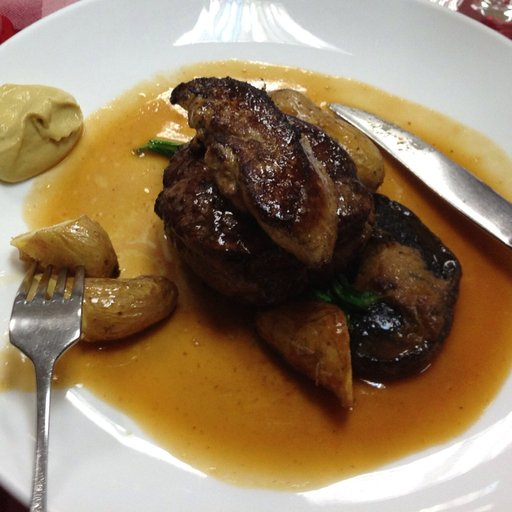

In [106]:
#Print metadata
print(f"Random image Path {random_image_path}")
print(f"Image_class {image_class}")
print(f"Image height {img.height}")
print(f"Image width {img.width}")
img

In [107]:
#Image using matplotlib

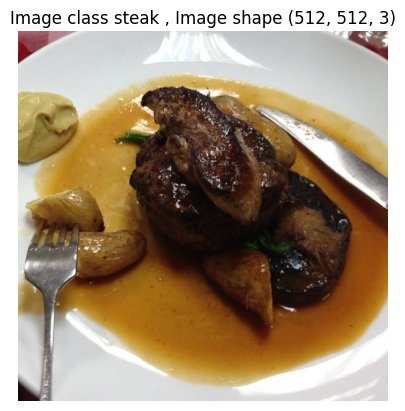

In [108]:
import numpy as np
import matplotlib.pyplot as plt
img_as_array=np.asarray(img)
plt.imshow(img_as_array)
plt.title(f"Image class {image_class} , Image shape {img_as_array.shape}")
plt.axis(False)
plt.show()

array([[[165,  98, 107],
        [163,  96, 105],
        [165,  98, 107],
        ...,
        [118,  83,  79],
        [162, 135, 128],
        [196, 173, 165]],

       [[163,  96, 105],
        [163,  96, 105],
        [165,  98, 107],
        ...,
        [142, 109, 104],
        [181, 156, 149],
        [197, 177, 168]],

       [[162,  97, 105],
        [163,  98, 106],
        [163,  98, 106],
        ...,
        [147, 118, 114],
        [193, 170, 164],
        [200, 181, 174]],

       ...,

       [[ 26,  10,  11],
        [ 27,  11,  12],
        [ 30,  11,  13],
        ...,
        [216, 211, 208],
        [216, 211, 208],
        [216, 211, 208]],

       [[ 29,  10,  12],
        [ 28,   9,  11],
        [ 27,   8,  10],
        ...,
        [216, 211, 208],
        [216, 211, 208],
        [216, 211, 208]],

       [[ 27,   8,  10],
        [ 24,   5,   7],
        [ 22,   3,   5],
        ...,
        [216, 211, 208],
        [216, 211, 208],
        [216, 211, 208]]], dtype=uint8)
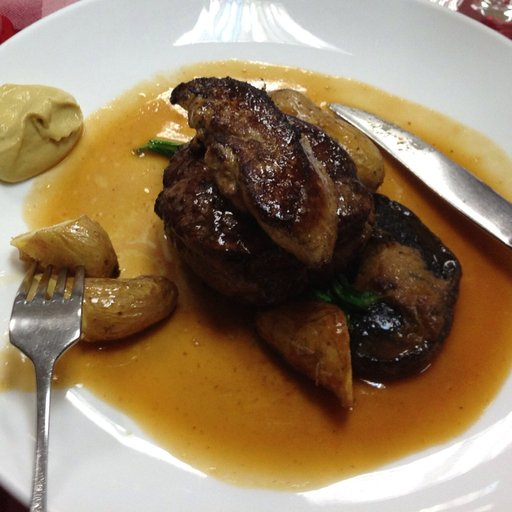

In [109]:
img_as_array

In [110]:
#Trainsforming data

In [111]:
import torch
from torch.utils.data import DataLoader
from torchvision import datasets,transforms

In [112]:
#Transforming data with torchvison.transforms

In [113]:
data_transform=transforms.Compose([
    transforms.Resize(size=(64,64)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor()
])

In [114]:
data_transform(img).shape

torch.Size([3, 64, 64])

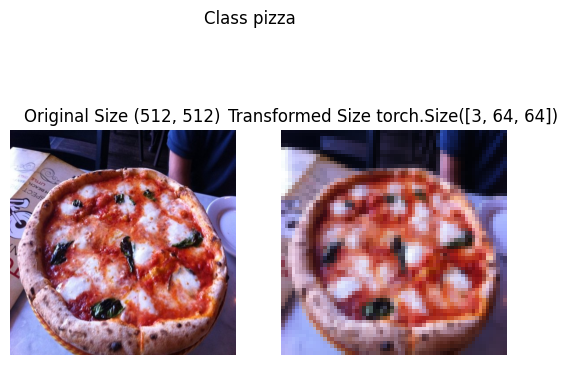

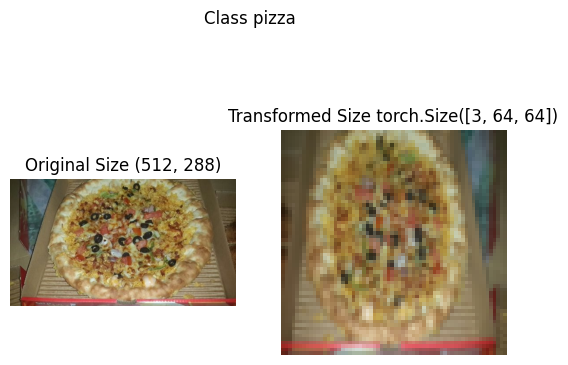

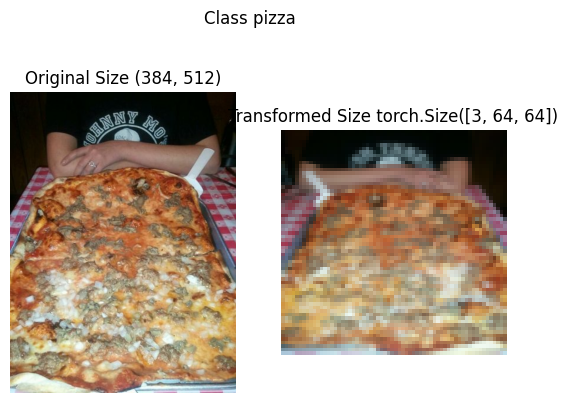

In [115]:
def plot_transformed_images(image_paths,transforms,n,seed=None):
  """Selects random images from a path of images and loads and transforms them plot the original vs transformed version"""
  if seed:
    random.seed(seed)
  random_image_paths=random.sample(image_paths,k=n)
  for image_path in random_image_paths:
    with Image.open(image_path) as f:
      fig,axs=plt.subplots(nrows=1,ncols=2)
      axs[0].imshow(f)
      axs[0].set_title(f"Original Size {f.size}")
      axs[0].axis(False)
      transformed_image=transforms(f) #We need to change shape for matplotlib remember
      axs[1].imshow(transformed_image.permute(1,2,0))
      axs[1].set_title(f"Transformed Size {transformed_image.shape}")
      axs[1].axis(False)
      fig.suptitle(f"Class {image_path.parent.stem}")
      plt.show()
plot_transformed_images(image_paths=image_path_list,transforms=data_transform,n=3)

In [116]:
#Loading image classification data using torchvision.datasets.transform

In [117]:
from torchvision import datasets
train_data=datasets.ImageFolder(root=train_dir,transform=data_transform,target_transform=None)
test_data=datasets.ImageFolder(root=test_dir,transform=data_transform,target_transform=None)

In [118]:
train_data,test_data

(Dataset ImageFolder
     Number of datapoints: 225
     Root location: data/pizza_streak_sushi/train
     StandardTransform
 Transform: Compose(
                Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
                RandomHorizontalFlip(p=0.5)
                ToTensor()
            ),
 Dataset ImageFolder
     Number of datapoints: 75
     Root location: data/pizza_streak_sushi/test
     StandardTransform
 Transform: Compose(
                Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
                RandomHorizontalFlip(p=0.5)
                ToTensor()
            ))

In [119]:
#Get class names as list
class_names=train_data.classes
class_names

['pizza', 'steak', 'sushi']

In [120]:
#Get class names as dictionary
class_dict=train_data.class_to_idx
class_dict

{'pizza': 0, 'steak': 1, 'sushi': 2}

In [121]:
len(train_data),len(test_data)

(225, 75)

In [122]:
train_data.samples[:5]

[('data/pizza_streak_sushi/train/pizza/1008844.jpg', 0),
 ('data/pizza_streak_sushi/train/pizza/1033251.jpg', 0),
 ('data/pizza_streak_sushi/train/pizza/1044789.jpg', 0),
 ('data/pizza_streak_sushi/train/pizza/1089334.jpg', 0),
 ('data/pizza_streak_sushi/train/pizza/1105700.jpg', 0)]

In [123]:
train_data.targets[:5]

[0, 0, 0, 0, 0]

In [124]:
train_data[0]

(tensor([[[0.1137, 0.1020, 0.0980,  ..., 0.1255, 0.1216, 0.1176],
          [0.1059, 0.0980, 0.0980,  ..., 0.1294, 0.1294, 0.1294],
          [0.1020, 0.0980, 0.0941,  ..., 0.1333, 0.1333, 0.1333],
          ...,
          [0.1098, 0.1098, 0.1255,  ..., 0.1686, 0.1647, 0.1686],
          [0.0902, 0.0941, 0.1098,  ..., 0.1686, 0.1647, 0.1686],
          [0.0863, 0.0863, 0.0980,  ..., 0.1686, 0.1647, 0.1647]],
 
         [[0.0745, 0.0706, 0.0745,  ..., 0.0588, 0.0588, 0.0588],
          [0.0745, 0.0706, 0.0745,  ..., 0.0627, 0.0627, 0.0627],
          [0.0706, 0.0745, 0.0745,  ..., 0.0706, 0.0706, 0.0706],
          ...,
          [0.1255, 0.1333, 0.1373,  ..., 0.2510, 0.2392, 0.2392],
          [0.1098, 0.1176, 0.1255,  ..., 0.2510, 0.2392, 0.2314],
          [0.1020, 0.1059, 0.1137,  ..., 0.2431, 0.2353, 0.2275]],
 
         [[0.0941, 0.0902, 0.0902,  ..., 0.0157, 0.0196, 0.0196],
          [0.0902, 0.0863, 0.0902,  ..., 0.0196, 0.0157, 0.0196],
          [0.0902, 0.0902, 0.0902,  ...,

In [125]:
image=train_data[0][0]
image_label=train_data[0][1]

In [126]:
image.shape,image_label

(torch.Size([3, 64, 64]), 0)

In [127]:
image

tensor([[[0.1176, 0.1216, 0.1255,  ..., 0.0980, 0.1020, 0.1137],
         [0.1294, 0.1294, 0.1294,  ..., 0.0980, 0.0980, 0.1059],
         [0.1333, 0.1333, 0.1333,  ..., 0.0941, 0.0980, 0.1020],
         ...,
         [0.1686, 0.1647, 0.1686,  ..., 0.1255, 0.1098, 0.1098],
         [0.1686, 0.1647, 0.1686,  ..., 0.1098, 0.0941, 0.0902],
         [0.1647, 0.1647, 0.1686,  ..., 0.0980, 0.0863, 0.0863]],

        [[0.0588, 0.0588, 0.0588,  ..., 0.0745, 0.0706, 0.0745],
         [0.0627, 0.0627, 0.0627,  ..., 0.0745, 0.0706, 0.0745],
         [0.0706, 0.0706, 0.0706,  ..., 0.0745, 0.0745, 0.0706],
         ...,
         [0.2392, 0.2392, 0.2510,  ..., 0.1373, 0.1333, 0.1255],
         [0.2314, 0.2392, 0.2510,  ..., 0.1255, 0.1176, 0.1098],
         [0.2275, 0.2353, 0.2431,  ..., 0.1137, 0.1059, 0.1020]],

        [[0.0196, 0.0196, 0.0157,  ..., 0.0902, 0.0902, 0.0941],
         [0.0196, 0.0157, 0.0196,  ..., 0.0902, 0.0863, 0.0902],
         [0.0196, 0.0157, 0.0157,  ..., 0.0902, 0.0902, 0.

In [128]:
class_names[image_label]

'pizza'

Shape of image torch.Size([3, 64, 64])
Shape of Permuted image torch.Size([64, 64, 3])


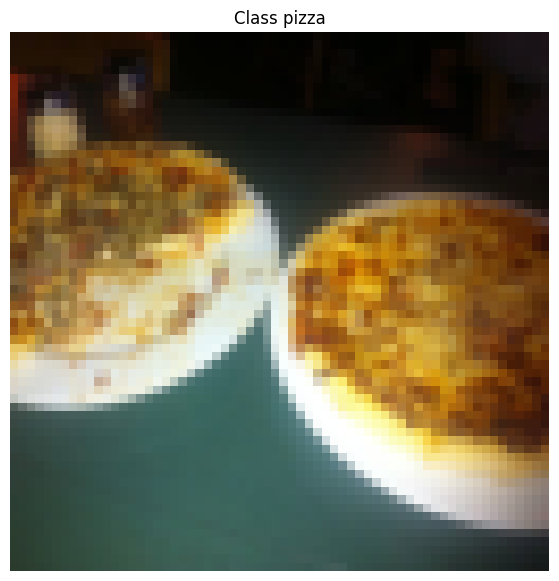

In [129]:
image_permute=image.permute(1,2,0)
print(f"Shape of image {image.shape}")
print(f"Shape of Permuted image {image_permute.shape}")
#Plot image
plt.figure(figsize=(10,7))
plt.imshow(image_permute)
plt.title(f"Class {class_names[image_label]}")
plt.axis(False)
plt.show()

In [130]:
import os
os.cpu_count()

2

In [131]:
#Turn Train and test datasets into into dataloaders
from torch.utils.data import DataLoader
train_dataloader=DataLoader(
    dataset=train_data,
    batch_size=32,
    num_workers=1,
    shuffle=True
)

In [132]:
test_dataloader=DataLoader(
    dataset=test_data,
    batch_size=32,
    num_workers=1,
    shuffle=False
)

In [133]:
train_dataloader,test_dataloader

(<torch.utils.data.dataloader.DataLoader at 0x7fddc00a9f20>,
 <torch.utils.data.dataloader.DataLoader at 0x7fddc00aaad0>)

In [134]:
len(train_dataloader),len(test_dataloader)

(8, 3)

In [135]:
img,label=next(iter(train_dataloader))

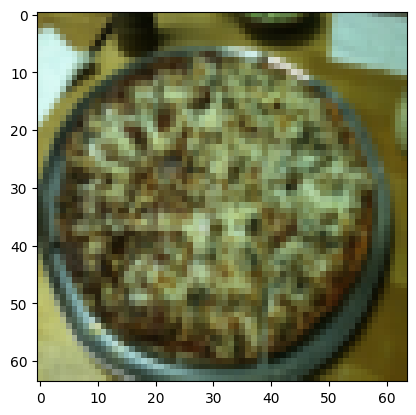

In [136]:
plt.imshow(img[0].permute(1,2,0))

In [137]:
import os
import pathlib
import torch
from PIL import Image
from torch.utils.data import Dataset
from torchvision import transforms
from typing import Tuple,Dict,List

In [138]:
train_data.classes,train_data.class_to_idx

(['pizza', 'steak', 'sushi'], {'pizza': 0, 'steak': 1, 'sushi': 2})

In [139]:
trarget_directory = train_dir

In [140]:
list(os.scandir(trarget_directory))

[<DirEntry 'pizza'>, <DirEntry 'sushi'>, <DirEntry 'steak'>]

In [141]:
#Get the class names from the target directory
class_names_found=sorted([entry.name for entry in list(os.scandir(trarget_directory))])
class_names

['pizza', 'steak', 'sushi']

In [142]:
list(os.scandir(trarget_directory))

[<DirEntry 'pizza'>, <DirEntry 'sushi'>, <DirEntry 'steak'>]

In [143]:
#Lets turn it into function

In [144]:
def find_classes(directory:str)->Tuple[List[str],Dict[str,int]]:
  #1.Get the class names by scanning the target directory
  classes=sorted(entry.name for entry in os.scandir(directory) if entry.is_dir())
  if not classes:
    raise FileNotFoundError(f"Couldn't find any classes in {directory}")
  #2.Create a class to index dictionary
  class_to_idx={cls_name:i for i,cls_name in enumerate(classes)}
  return classes,class_to_idx

In [145]:
find_classes(train_dir)

(['pizza', 'steak', 'sushi'], {'pizza': 0, 'steak': 1, 'sushi': 2})

In [146]:
#Create custom dataset to replicate 'ImageFolder'

In [147]:
from torch.utils.data import Dataset
#Subclass torch.utils.data.Dataset
class ImageFolderCustom(Dataset):
  #Initialize custom dataset
  def __init__(self,targ_dir:str,transform=None):
    #Create class attributes
    self.paths=list(pathlib.Path(targ_dir).glob("*/*.jpg"))
    #Setup transform
    self.transform=transform
    #Create class and class to idx
    self.classes,self.class_to_idx=find_classes(targ_dir)
  #Create function to load_image
  def load_image(self,index:int)->Image.Image:
    return Image.open(self.paths[index])
  def __len__(self)->int:
    #Returns total number of samples
    return len(self.paths)
  #Owerright __getitem__ method to return a particular sample
  def __getitem__(self,index:int)->Tuple[torch.Tensor,int]:
    image=self.load_image(index)
    class_name=self.paths[index].parent.name
    class_idx=self.class_to_idx[class_name]
    if self.transform:
      return self.transform(image),class_idx
    else:
      return image,class_idx

In [148]:
from torchvision.transforms import transforms
train_transform=transforms.Compose([
    transforms.Resize(size=(64,64)),
    transforms.ToTensor()
])
test_transform=transforms.Compose([
    transforms.Resize(size=(64,64)),
    transforms.ToTensor()
])

In [149]:
train_data_custom=ImageFolderCustom(train_dir,transform=train_transform)

In [150]:
test_data_custom=ImageFolderCustom(test_dir,transform=test_transform)

In [151]:
train_data_custom

In [152]:
test_data_custom

In [153]:
len(train_data),len(train_data_custom)

(225, 225)

In [154]:
len(test_data),len(test_data_custom)

(75, 75)

In [155]:
train_data_custom.class_to_idx

{'pizza': 0, 'steak': 1, 'sushi': 2}

In [156]:
train_data_custom.classes

['pizza', 'steak', 'sushi']

In [157]:
print(train_data_custom.classes==train_data.classes)

True


In [158]:
#Create function to visualize random images
def display_random_images(dataset:torch.utils.data.Dataset,classes:[List]=None,n:int=10,display_shape:bool=True,seed:int=None):
  if n>10:
    n=10
    display_shape=False
    print("For display purposes n should not be larger than 10,setting to 10 and removing shape display")
  if seed:
    random.seed(seed)
  #Get random sample indeces
  random_sample_indeces=random.sample(range(len(dataset)),k=n)
  #Loop through random indeces and plot them
  plt.figure(figsize=(16,8))
  for i,targ_sample in enumerate(random_sample_indeces):
    img,label=dataset[targ_sample][0],dataset[targ_sample][1]
    plt.subplot(1,n,i+1)
    plt.imshow(img.permute(1,2,0))
    plt.axis('off')
    if classes:
      title=classes[label]
      if display_shape:
        title=f"{title} {img.shape}"
      plt.title(title)
  plt.show()

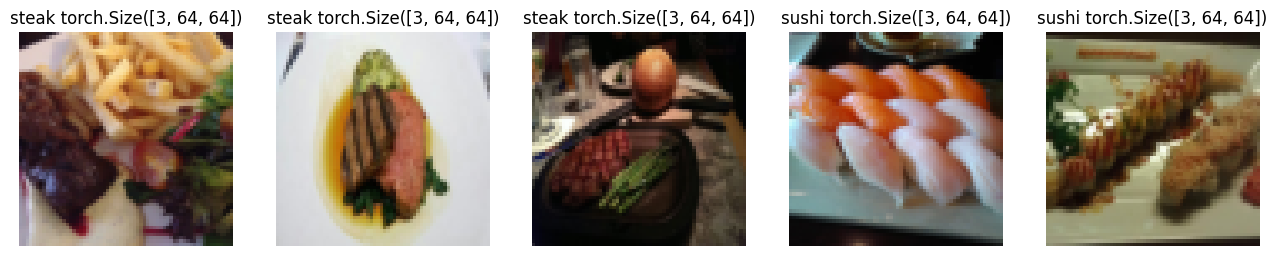

In [159]:
display_random_images(dataset=train_data,classes=class_names,n=5,display_shape=True,seed=44)

In [160]:
#Turn custom loaded images to dataloader

In [161]:
from torch.utils.data import DataLoader
train_custom_dataloader=DataLoader(
    dataset=train_data_custom,
    batch_size=32,
    num_workers=os.cpu_count(),
    shuffle=True
)
test_custom_dataloader=DataLoader(
    dataset=test_data_custom,
    batch_size=32,
    num_workers=os.cpu_count(),
    shuffle=False
)

In [162]:
train_custom_dataloader,test_custom_dataloader

(<torch.utils.data.dataloader.DataLoader at 0x7fddf0aa0750>,
 <torch.utils.data.dataloader.DataLoader at 0x7fddf0aa0d50>)

In [163]:
img_custom,label_custom=next(iter(train_custom_dataloader))

In [164]:
img_custom.shape

torch.Size([32, 3, 64, 64])

In [165]:
#Other forms of transfoms(data aurgumentation)

In [166]:
from torchvision import transforms
train_transforms=transforms.Compose([
    transforms.Resize(size=(64,64)),
    transforms.TrivialAugmentWide(num_magnitude_bins=31),
    transforms.ToTensor()
])
test_transforms=transforms.Compose([
    transforms.Resize(size=(64,64)),
    transforms.ToTensor()
])


In [167]:
image_path_list=list(image_path.glob("*/*/*.jpg"))

In [168]:
image_path_list[:10]

[PosixPath('data/pizza_streak_sushi/test/pizza/2236338.jpg'),
 PosixPath('data/pizza_streak_sushi/test/pizza/1503858.jpg'),
 PosixPath('data/pizza_streak_sushi/test/pizza/1152100.jpg'),
 PosixPath('data/pizza_streak_sushi/test/pizza/194643.jpg'),
 PosixPath('data/pizza_streak_sushi/test/pizza/1687143.jpg'),
 PosixPath('data/pizza_streak_sushi/test/pizza/2871261.jpg'),
 PosixPath('data/pizza_streak_sushi/test/pizza/3092704.jpg'),
 PosixPath('data/pizza_streak_sushi/test/pizza/2019408.jpg'),
 PosixPath('data/pizza_streak_sushi/test/pizza/930553.jpg'),
 PosixPath('data/pizza_streak_sushi/test/pizza/2218680.jpg')]

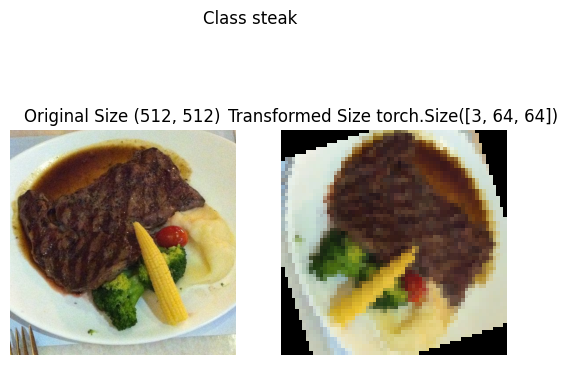

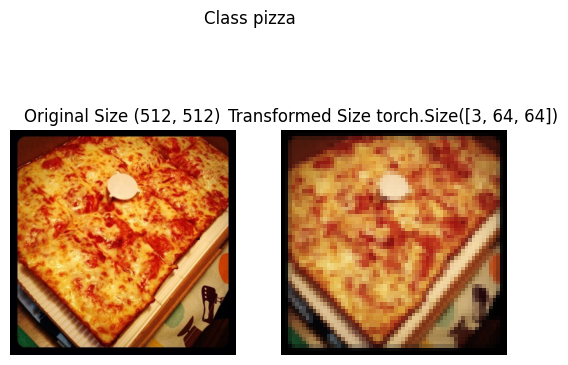

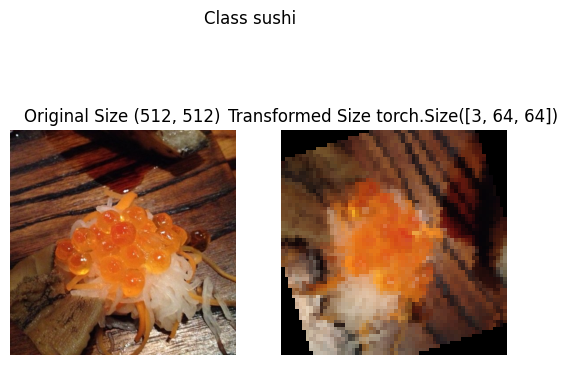

In [169]:
plot_transformed_images(image_paths=image_path_list,transforms=train_transforms,n=3,seed=None)

In [170]:
#Creating model_0

In [202]:
#Creating transorm
from torchvision import transforms
simple_transform=transforms.Compose(
    [
        transforms.Resize(size=(64,64)),
        transforms.ToTensor()
    ]
)

In [203]:
#Loading image Data from image folder
from torchvision import datasets
train_data_simple=datasets.ImageFolder(root=train_dir,transform=simple_transform,target_transform=None)
test_data_simple=datasets.ImageFolder(root=test_dir,transform=simple_transform,target_transform=None)

In [204]:
#Turn dataset into dataloader
from torch.utils.data import DataLoader
import os
train_dataloader_simple=DataLoader(
    dataset=train_data_simple,
    batch_size=32,
    num_workers=os.cpu_count(),
    shuffle=True
)
test_dataloader_simple=DataLoader(
    dataset=test_data_simple,
    batch_size=32,
    num_workers=os.cpu_count(),
    shuffle=False

)

In [205]:
class TinyVGG(nn.Module):
  def __init__(self,input_shape:int,hidden_unit:int,output_shape:int) -> None:
    super().__init__()
    self.conv_block_1=nn.Sequential(
        nn.Conv2d(in_channels=input_shape,out_channels=hidden_unit,kernel_size=3,stride=1,padding=1),
        nn.ReLU(),
        nn.Conv2d(in_channels=hidden_unit,out_channels=hidden_unit,kernel_size=3,stride=1,padding=1),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2,stride=2)
    )
    self.conv_block_2=nn.Sequential( # Renamed from conv_block_1 to conv_block_2
        nn.Conv2d(in_channels=hidden_unit,out_channels=hidden_unit,kernel_size=3,stride=1,padding=1),
        nn.ReLU(),
        nn.Conv2d(in_channels=hidden_unit,out_channels=hidden_unit,kernel_size=3,stride=1,padding=1),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2,stride=2)
    )
    self.classifier_layer=nn.Sequential(
        nn.Flatten(),
        # Adjust in_features based on the output of conv_block_2 (hidden_unit * 16 * 16 for 64x64 input)
        nn.Linear(in_features=hidden_unit*16*16, out_features=output_shape)
    )
  def forward(self,x):
    x=self.conv_block_1(x)

    x=self.conv_block_2(x)

    x=self.classifier_layer(x)
    return x

In [206]:
model_0=TinyVGG(input_shape=3,hidden_unit=32,output_shape=len(class_names)).to(device)

In [207]:
#Try forward pass on a single image
image_batch,label_batch=next(iter(train_dataloader_simple))

In [208]:
image_batch.shape,label_batch.shape

(torch.Size([32, 3, 64, 64]), torch.Size([32]))

In [209]:
#Try forward pass
model_0(image_batch.to(device))

tensor([[-0.0058,  0.0106, -0.0058],
        [-0.0056,  0.0123, -0.0048],
        [-0.0065,  0.0133, -0.0084],
        [-0.0084,  0.0110, -0.0075],
        [-0.0077,  0.0148, -0.0093],
        [-0.0058,  0.0108, -0.0065],
        [-0.0045,  0.0091, -0.0068],
        [-0.0070,  0.0129, -0.0060],
        [-0.0057,  0.0104, -0.0042],
        [-0.0088,  0.0091, -0.0062],
        [-0.0064,  0.0122, -0.0055],
        [-0.0056,  0.0154, -0.0077],
        [-0.0027,  0.0121, -0.0067],
        [-0.0052,  0.0110, -0.0072],
        [-0.0044,  0.0127, -0.0042],
        [-0.0060,  0.0093, -0.0051],
        [-0.0089,  0.0127, -0.0100],
        [-0.0045,  0.0148, -0.0084],
        [-0.0099,  0.0144, -0.0080],
        [-0.0046,  0.0100, -0.0072],
        [-0.0062,  0.0104, -0.0065],
        [-0.0062,  0.0127, -0.0073],
        [-0.0060,  0.0125, -0.0064],
        [-0.0126,  0.0117, -0.0026],
        [-0.0048,  0.0113, -0.0016],
        [-0.0051,  0.0106, -0.0071],
        [-0.0066,  0.0068, -0.0027],
 

In [210]:
#Getting Summary of our model
from torchsummary import summary
summary(model_0,input_size=(3,64,64))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 32, 64, 64]             896
              ReLU-2           [-1, 32, 64, 64]               0
            Conv2d-3           [-1, 32, 64, 64]           9,248
              ReLU-4           [-1, 32, 64, 64]               0
         MaxPool2d-5           [-1, 32, 32, 32]               0
            Conv2d-6           [-1, 32, 32, 32]           9,248
              ReLU-7           [-1, 32, 32, 32]               0
            Conv2d-8           [-1, 32, 32, 32]           9,248
              ReLU-9           [-1, 32, 32, 32]               0
        MaxPool2d-10           [-1, 32, 16, 16]               0
          Flatten-11                 [-1, 8192]               0
           Linear-12                    [-1, 3]          24,579
Total params: 53,219
Trainable params: 53,219
Non-trainable params: 0
---------------------------------

In [211]:
#Create function for train and test step

In [212]:
def train_step(model, dataloader, loss_fn, optimizer):

    model.train()

    train_loss = 0
    correct = 0
    total = 0

    for batch, (x, y) in enumerate(dataloader):

        x, y = x.to(device), y.to(device)

        # Forward pass
        y_logits = model(x)

        # Predictions
        y_pred = y_logits.argmax(dim=1)

        # Calculate loss
        loss = loss_fn(y_logits, y)

        # Backpropagation
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # Accumulate loss
        train_loss += loss.item()

        # Accumulate correct predictions
        correct += (y_pred == y).sum().item()
        total += y.size(0)

    # Average loss
    train_loss = train_loss / len(dataloader)

    # Accuracy
    train_acc = correct / total

    return train_loss, train_acc

In [213]:
def test_step(model, dataloader, loss_fn):

    model.eval()

    test_loss = 0
    correct = 0
    total = 0

    with torch.inference_mode():

        for batch, (x, y) in enumerate(dataloader):

            x, y = x.to(device), y.to(device)

            # Forward pass
            y_logits = model(x)

            # Predictions
            y_pred = y_logits.argmax(dim=1)

            # Calculate loss
            loss = loss_fn(y_logits, y)

            # Accumulate loss
            test_loss += loss.item()

            # Accumulate correct predictions
            correct += (y_pred == y).sum().item()
            total += y.size(0)

    # Average loss
    test_loss = test_loss / len(dataloader)

    # Accuracy
    test_acc = correct / total

    return test_loss, test_acc

In [218]:
loss_fn = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    params=model_0.parameters(),
    lr=0.001
)

In [219]:
from tqdm.auto import tqdm
torch.manual_seed(42)
torch.cuda.manual_seed(42)
epochs=5
for epoch in tqdm(range(epochs)):
  train_loss,train_acc=train_step(model=model_0,dataloader=train_dataloader_simple,loss_fn=loss_fn,optimizer=optimizer)
  test_loss,test_acc=test_step(model=model_0,dataloader=test_dataloader_simple,loss_fn=loss_fn)
  print(f"epoch:{epoch+1} train_loss:{train_loss} train_acc:{train_acc} test_loss:{test_loss} test_acc:{test_acc}")


  0%|          | 0/5 [00:00<?, ?it/s]

epoch:1 train_loss:1.0896736979484558 train_acc:0.3466666666666667 test_loss:1.1284948984781902 test_acc:0.3333333333333333
epoch:2 train_loss:1.075389288365841 train_acc:0.39555555555555555 test_loss:1.1233264803886414 test_acc:0.4
epoch:3 train_loss:1.0422217100858688 train_acc:0.43555555555555553 test_loss:1.081490973631541 test_acc:0.38666666666666666
epoch:4 train_loss:0.8645242936909199 train_acc:0.5333333333333333 test_loss:1.0261593858400981 test_acc:0.48
epoch:5 train_loss:0.894621841609478 train_acc:0.5866666666666667 test_loss:1.0167415340741475 test_acc:0.44


In [216]:
print(train_data_simple.classes)
print(train_data_simple.class_to_idx)

from collections import Counter

print("Train:", Counter(train_data_simple.targets))
print("Test:", Counter(test_data_simple.targets))

['pizza', 'steak', 'sushi']
{'pizza': 0, 'steak': 1, 'sushi': 2}
Train: Counter({0: 78, 1: 75, 2: 72})
Test: Counter({2: 31, 0: 25, 1: 19})


In [221]:
model_0.eval()

images, labels = next(iter(test_dataloader_simple))

with torch.inference_mode():
    logits = model_0(images.to(device))
    predictions = logits.argmax(dim=1)

print("Predictions:", predictions)
print("Actual:", labels)

print("Prediction distribution:", Counter(predictions.cpu().tolist()))

Predictions: tensor([2, 0, 0, 0, 2, 1, 2, 2, 0, 1, 1, 0, 1, 0, 0, 0, 0, 2, 2, 2, 2, 1, 2, 2,
        0, 1, 2, 1, 2, 0, 1, 1])
Actual: tensor([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 1, 1, 1, 1, 1, 1, 1])
Prediction distribution: Counter({2: 12, 0: 11, 1: 9})
